# Dataset exploration

Loads the processed SemEval-2014 Task 4 records and reports the statistics the models and the report rely on: size, label balance, aspect frequency, review length and the sentences that carry no aspect annotation.

## Setup

Run this on a Colab GPU runtime (*Runtime → Change runtime type → GPU*). The cell clones the repository, installs the dependencies and checks the environment. Colab keeps its own `torch`, so it is left as it is.

In [1]:
import os

if not os.path.isdir("aspect-based-sentiment-analysis"):
    !git clone -q https://github.com/Shivam-Shukla0/aspect-based-sentiment-analysis.git
%cd aspect-based-sentiment-analysis
!pip install -q -r requirements.txt
!pip install -q -e . --no-deps
!python -m scripts.verify_environment --require-gpu

/content/run/aspect-based-sentiment-analysis


  Installing build dependencies ... done


  Checking if build backend supports build_editable ... done


  Getting requirements to build editable ... done


  Preparing editable metadata (pyproject.toml) ... done
  Building editable for absa (pyproject.toml) ... done


python          3.13.16
numpy           2.4.6
pandas          2.2.3
scikit-learn    1.6.1
lxml            6.1.3
torch           2.14.1+cu130
transformers    5.22.1
accelerate      1.15.0
sentencepiece   0.2.2
matplotlib      3.10.0
flask           3.1.3
absa            0.1.0
device          NVIDIA L4 (CUDA 13.0, 1 device)
environment ok


## Data

The official SemEval-2014 Task 4 files are distributed through the ILSP Metashare repository and need an account and acceptance of its licence (see `data/README.md`). This cell uses those files when they are in Google Drive (set `USE_DRIVE = True` after mounting Drive), and otherwise downloads the same four files from a public Hugging Face mirror of the dataset. The mirror did not come through the official route, so the file checksums are printed and the report states this limitation. Nothing in `data/` is committed to Git.

In [2]:
from pathlib import Path

USE_DRIVE = False  # True: copy the official files from DRIVE_DIR (mount Drive first)
DRIVE_DIR = Path("/content/drive/MyDrive/absa/semeval2014")
MIRROR = "https://huggingface.co/datasets/alexcadillon/SemEval2014Task4/resolve/main"
TRAIN = "SemEval%2714-ABSA-TrainData_v2%20%26%20AnnotationGuidelines"
FILES = {
    "Laptop_Train_v2.xml": (f"{MIRROR}/{TRAIN}/Laptop_Train_v2.xml", "laptop", "train"),
    "Restaurants_Train_v2.xml": (f"{MIRROR}/{TRAIN}/Restaurants_Train_v2.xml", "restaurant", "train"),
    "Laptops_Test_Gold.xml": (f"{MIRROR}/ABSA_Gold_TestData/Laptops_Test_Gold.xml", "laptop", "test"),
    "Restaurants_Test_Gold.xml": (
        f"{MIRROR}/ABSA_Gold_TestData/Restaurants_Test_Gold.xml",
        "restaurant",
        "test",
    ),
}
Path("data/raw").mkdir(parents=True, exist_ok=True)
for name, (url, domain, split) in FILES.items():
    if USE_DRIVE:
        !cp "{DRIVE_DIR / name}" data/raw/
    else:
        !curl -sL -o data/raw/{name} "{url}"
    !python -m scripts.build_processed data/raw/{name} --domain {domain} --split {split} > /dev/null
!sha256sum data/raw/*.xml
!wc -l data/processed/*.jsonl

aa3a30c9dd7e0eacf9b69e898eb4118a36c1b4f391a30a08dfc41a38d8b8745b  data/raw/Laptops_Test_Gold.xml
efec2ed73b4efb83b47c697114d800149c558118884afa80362a6e975ba7248c  data/raw/Laptop_Train_v2.xml
f21509cfa37e16534cd5b2da043be487355b64ef48fe8d6aaacaeca6b49cc0fb  data/raw/Restaurants_Test_Gold.xml
223601da1bded6caa4ef9cf91a7007578141ca6d8ed50d5a5c217565f89d2fc5  data/raw/Restaurants_Train_v2.xml


    654 data/processed/laptop_test.jsonl
    378 data/processed/laptop_test_no_aspect.jsonl
   2358 data/processed/laptop_train.jsonl
   1557 data/processed/laptop_train_no_aspect.jsonl
   1134 data/processed/restaurant_test.jsonl
    194 data/processed/restaurant_test_no_aspect.jsonl
   3693 data/processed/restaurant_train.jsonl
   1020 data/processed/restaurant_train_no_aspect.jsonl
  10988 total


## Size and label balance

The `conflict` label is rare, and the models are trained and scored without it (see the report for the protocol).

In [3]:
import json
from collections import Counter

from absa.data import aspect_frequency, class_balance, review_lengths


def load(domain, split):
    with open(f"data/processed/{domain}_{split}.jsonl", encoding="utf-8") as handle:
        return [json.loads(line) for line in handle]


for domain in ("laptop", "restaurant"):
    for split in ("train", "test"):
        records = load(domain, split)
        print(f"{domain:10s} {split:5s} {len(records):5d} records  {class_balance(records)}")

laptop     train  2358 records  {'neutral': 460, 'positive': 987, 'negative': 866, 'conflict': 45}
laptop     test    654 records  {'positive': 341, 'negative': 128, 'neutral': 169, 'conflict': 16}
restaurant train  3693 records  {'negative': 805, 'positive': 2164, 'neutral': 633, 'conflict': 91}
restaurant test   1134 records  {'positive': 728, 'conflict': 14, 'neutral': 196, 'negative': 196}


## Aspect frequency and review length

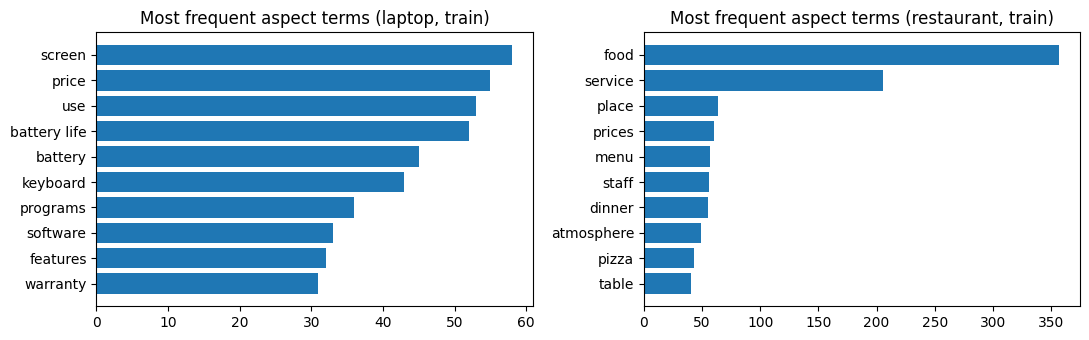

laptop: review length min 11, max 464, mean 104.9 characters
restaurant: review length min 10, max 357, mean 96.7 characters


In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, domain in zip(axes, ("laptop", "restaurant")):
    top = aspect_frequency(load(domain, "train"), top_n=10)
    ax.barh([a for a, _ in top][::-1], [c for _, c in top][::-1])
    ax.set_title(f"Most frequent aspect terms ({domain}, train)")
plt.tight_layout()
plt.show()

for domain in ("laptop", "restaurant"):
    lengths = review_lengths(load(domain, "train"))
    print(f"{domain}: review length min {min(lengths)}, max {max(lengths)}, mean {sum(lengths) / len(lengths):.1f} characters")

## Sentences without an aspect term

These are kept in separate files rather than dropped, because they matter for end-to-end evaluation.

In [5]:
for domain in ("laptop", "restaurant"):
    for split in ("train", "test"):
        with open(f"data/processed/{domain}_{split}_no_aspect.jsonl", encoding="utf-8") as handle:
            print(domain, split, sum(1 for _ in handle), "sentences without an aspect term")

laptop train 1557 sentences without an aspect term
laptop test 378 sentences without an aspect term
restaurant train 1020 sentences without an aspect term
restaurant test 194 sentences without an aspect term
